# Assignment No. 1

In [ ]:
pip install pandas numpy matplotlib seaborn scikit-learn openpyxl requests

In [ ]:

# Assignment No. 1
# Analyzing Sales Data from Multiple File Formats

# Import required libraries
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression


# STEP 1: Create sample datasets in different formats

# First dataset in dictionary format (will be saved as CSV)
# It contains duplicate IDs and missing Units values.
d1 = {
    "ID": [1, 2, 2],
    "Date": ["2024-01-10", "2024-01-15", "2024-01-15"],
    "Region": ["North", "South", "South"],
    "Cat": ["Tech", "Home", "Home"],
    "Units": [5, None, None],
    "Price": [1200, 80, 80],
    "AdSpend": [3000, 800, 800]
}

# Second dataset (will be saved as Excel)
d2 = {
    "ID": [3, 4],
    "Date": ["2024-02-01", "2024-02-15"],
    "Region": ["West", "East"],
    "Cat": ["Tech", "Cloth"],
    "Units": [10, 25],
    "Price": [1100, 40],
    "AdSpend": [2500, 1200]
}

# Third dataset (will be saved as JSON)
d3 = [{
    "ID": 5,
    "Date": "2024-03-01",
    "Region": "North",
    "Cat": "Cloth",
    "Units": 30,
    "Price": 35,
    "AdSpend": 1500
}]

# Save datasets in their respective file formats
pd.DataFrame(d1).to_csv("sales.csv", index=False)

pd.DataFrame(d2).to_excel("sales.xlsx", index=False)

with open("sales.json", "w") as f:
    json.dump(d3, f)


# STEP 2: Load and combine all datasets

# Read CSV, Excel and JSON files using pandas
# concat() combines all three datasets into one DataFrame
# ignore_index=True creates a fresh continuous index.

df = pd.concat([
    pd.read_csv("sales.csv"),
    pd.read_excel("sales.xlsx"),
    pd.read_json("sales.json")
], ignore_index=True)


# STEP 3: Data Cleaning

# Remove duplicate records based on ID.
# keep="first" keeps the first occurrence of each ID.
df.drop_duplicates(subset=["ID"], inplace=True)

# Replace missing Units values with the median of the column.
# Median is used to fill missing numerical values.
df["Units"] = df["Units"].fillna(df["Units"].median())


# STEP 4: Data Transformation

# Calculate total sales using Units multiplied by Price.
df["TotalSales"] = df["Units"] * df["Price"]

# Convert Date column from string format to datetime format.
df["Date"] = pd.to_datetime(df["Date"])

print("--- Cleaned Unified Data ---\n", df)


# STEP 5: Data Analysis

# Calculate total revenue from all sales.
print(f"\nTotal Revenue: INR {df['TotalSales'].sum():,.2f}")

# Calculate total sales for each product category.
print("\nSales by Category:\n",
      df.groupby("Cat")["TotalSales"].sum())

# Calculate total sales for each region.
print("\nSales by Region:\n",
      df.groupby("Region")["TotalSales"].sum())

# Calculate correlation between Total Sales and Advertisement Spend.
# Correlation indicates how strongly two numerical variables are related.
print(f"\nAd Spend Correlation: {df['TotalSales'].corr(df['AdSpend']):.4f}")


# STEP 6: Predictive Modeling using Linear Regression

# Create X (independent variable) using row positions.
# reshape(-1, 1) converts the array into a 2D format.
X = np.arange(len(df)).reshape(-1, 1)

# Y (dependent variable) is TotalSales.
# Train the Linear Regression model using existing sales data.
model = LinearRegression().fit(X, df["TotalSales"])

# Predict the next sales value.
print(f"\nNext Order Forecast: INR {model.predict([[len(df)]])[0]:,.2f}")


# STEP 7: Data Visualization

# Create two plots side by side.
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Bar chart showing total revenue by product category.
df.groupby("Cat")["TotalSales"].sum().plot(
    kind="bar",
    ax=ax[0],
    title="Revenue by Category",
    color="steelblue"
)

# Pie chart showing revenue distribution by region.
df.groupby("Region")["TotalSales"].sum().plot(
    kind="pie",
    ax=ax[1],
    autopct="%1.0f%%",
    title="Revenue by Region"
)

# Adjust spacing between plots.
plt.tight_layout()

# Display both visualizations.
plt.show()


# Assignment No. 2

Replace the API key placeholder with your own OpenWeatherMap key to fetch live forecast data. The notebook uses generated sample data if the API request does not return forecast results.

In [ ]:
import datetime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

# 1. Configuration
# Add your own OpenWeatherMap API key here.
API_KEY = "YOUR_OPENWEATHERMAP_API_KEY"
CITY = "Pune"
URL = f"https://api.openweathermap.org/data/2.5/forecast?q={CITY}&units=metric&appid={API_KEY}"

# 2. Fetch API data with error checking and automatic fallbacka
# Assignment No. 2
# Analyzing Weather Data from OpenWeatherMap API

# Import required libraries
import datetime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests


# STEP 1: Configuration

# API key is required to access weather data from OpenWeatherMap.
# Replace the placeholder with your actual API key.
API_KEY = "3f2d853c29aa9462c2f9c3a8a14265f3"

# Specify the city for which weather data is required.
CITY = "Pune"

# Create the API URL.
# units=metric gives temperature in Celsius.
URL = f"https://api.openweathermap.org/data/2.5/forecast?q={CITY}&units=metric&appid={API_KEY}"


# STEP 2: Fetch Weather Data from API

# Send GET request to the OpenWeatherMap API.
res = requests.get(URL)

# Convert API response into JSON format if request is successful.
# Otherwise, use an empty dictionary.
data = res.json() if res.status_code == 200 else {}

# Check whether valid forecast data is available.
if "list" in data and len(data["list"]) > 0:

    # Store the weather forecast records.
    items = data["list"]

    print(f"Loaded live data for {CITY}")

else:

    # If API fails, generate sample weather data.
    # This allows the program to execute without live API access.
    print(f"API notice: Using sample data (status {res.status_code} - check API_KEY)")

    # Get the current date and time.
    now = datetime.datetime.now()

    # Generate 24 sample weather records at 3-hour intervals.
    items = [{
        "dt_txt": (now + datetime.timedelta(hours=i * 3)).strftime("%Y-%m-%d %H:%M:%S"),

        "main": {
            # Generate sample temperature values.
            "temp": round(28 + 5 * np.sin(i / 3), 1),

            # Generate sample humidity values.
            "humidity": int(65 + 15 * np.cos(i / 3))
        },

        # Sample wind speed.
        "wind": {"speed": 4.5},

        # Add sample rainfall for selected intervals.
        "rain": {"3h": 0.5 if i % 4 == 0 else 0.0}

    } for i in range(24)]


# STEP 3: Extract and Clean Weather Data

# Extract required attributes from the API response.
# Store datetime, temperature, humidity, wind speed and rainfall.
records = [{
    "datetime": item["dt_txt"],
    "temp": item["main"]["temp"],
    "humidity": item["main"]["humidity"],
    "wind_speed": item["wind"]["speed"],
    "rain": item.get("rain", {}).get("3h", 0.0)
} for item in items]

# Convert extracted records into a Pandas DataFrame.
df = pd.DataFrame(records)

# Convert datetime column from string to datetime format.
df["datetime"] = pd.to_datetime(df["datetime"])

# Extract only the date from datetime.
df["date"] = df["datetime"].dt.date


# STEP 4: Data Aggregation and Analysis

# Group weather records by date.
# Calculate average temperature and humidity.
# Calculate total rainfall for each day.
daily = df.groupby("date").agg({
    "temp": "mean",
    "humidity": "mean",
    "rain": "sum"
})

# Display daily weather summary.
print("\n--- Daily Weather Summary ---\n", daily)

# Calculate correlation between temperature and humidity.
# Correlation shows the relationship between these two variables.
print(f"\nTemp vs Humidity Correlation: {df['temp'].corr(df['humidity']):.2f}")


# STEP 5: Data Visualization

# Create a figure for the temperature trend.
plt.figure(figsize=(8, 4))

# Plot temperature against date and time.
plt.plot(
    df["datetime"],
    df["temp"],
    marker="o",
    color="tomato",
    label="Temp (°C)"
)

# Add chart title and axis labels.
plt.title(f"Weather Forecast - {CITY}")
plt.xlabel("Date & Time")
plt.ylabel("Temperature (°C)")

# Rotate date labels for better readability.
plt.xticks(rotation=30)

# Adjust the layout.
plt.tight_layout()

# Display the temperature trend graph.
plt.show()

res = requests.get(URL)
data = res.json() if res.status_code == 200 else {}

if "list" in data and len(data["list"]) > 0:
    items = data["list"]
    print(f"Loaded live data for {CITY}")
else:
    print(f"API notice: Using sample data (status {res.status_code} - check API_KEY)")
    now = datetime.datetime.now()
    items = [{
        "dt_txt": (now + datetime.timedelta(hours=i * 3)).strftime("%Y-%m-%d %H:%M:%S"),
        "main": {
            "temp": round(28 + 5 * np.sin(i / 3), 1),
            "humidity": int(65 + 15 * np.cos(i / 3))
        },
        "wind": {"speed": 4.5},
        "rain": {"3h": 0.5 if i % 4 == 0 else 0.0}
    } for i in range(24)]

# 3. Extract and clean attributes into a DataFrame
records = [{
    "datetime": item["dt_txt"],
    "temp": item["main"]["temp"],
    "humidity": item["main"]["humidity"],
    "wind_speed": item["wind"]["speed"],
    "rain": item.get("rain", {}).get("3h", 0.0)
} for item in items]

df = pd.DataFrame(records)
df["datetime"] = pd.to_datetime(df["datetime"])
df["date"] = df["datetime"].dt.date

# 4. Modeling and aggregation (daily averages)
daily = df.groupby("date").agg({
    "temp": "mean",
    "humidity": "mean",
    "rain": "sum"
})
print("\\n--- Daily Weather Summary ---\\n", daily)
print(f"\\nTemp vs Humidity Correlation: {df['temp'].corr(df['humidity']):.2f}")

# 5. Visualization: Temperature trend
plt.figure(figsize=(8, 4))
plt.plot(df["datetime"], df["temp"], marker="o", color="tomato", label="Temp (°C)")
plt.title(f"Weather Forecast - {CITY}")
plt.xlabel("Date & Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Assignment No. 3

In [1]:

# Assignment 3: Telecom Customer Churn Data Cleaning and Preparation

# Import required libraries
import numpy as np
import pandas as pd

# Used to divide the dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Used to standardize numerical columns
from sklearn.preprocessing import StandardScaler


# --------------------------------------------------
# TASK 1: Import the dataset
# --------------------------------------------------

# Read the telecom customer churn CSV file
URL = "Telco-Customer-Churn.csv"
df = pd.read_csv(URL)

# Display the number of rows and columns
print("=== Task 1 & 2: Dataset Loaded & Shape ===")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")

# Display the first two records
print(df.head(2))


# --------------------------------------------------
# TASK 4: Remove duplicate records
# --------------------------------------------------

# Store the initial number of rows
init_rows = len(df)

# Remove duplicate customers using customerID
df.drop_duplicates(subset=["customerID"], inplace=True)

# Calculate how many duplicate rows were removed
print("\n=== Task 4: Duplicates Removed ===")
print(f"Removed: {init_rows - len(df)} duplicate rows")


# --------------------------------------------------
# TASK 5 & 6: Convert data types and detect missing values
# --------------------------------------------------

# Remove extra spaces from TotalCharges and convert it to numeric
# errors="coerce" converts invalid or blank values into NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(), errors="coerce"
)

# Count missing values in TotalCharges
print("\n=== Task 5 & 6: Missing/Blank Values Detected ===")
print("Null TotalCharges count:", df["TotalCharges"].isnull().sum())


# --------------------------------------------------
# TASK 3: Handle missing values
# --------------------------------------------------

# Replace missing TotalCharges values using:
# tenure * MonthlyCharges
# This estimates the total amount charged to the customer
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["tenure"] * df["MonthlyCharges"]
)

# Check whether any missing values remain in the dataset
print(
    f"Remaining null values across dataset: "
    f"{df.isnull().sum().sum()}"
)


# --------------------------------------------------
# TASK 7: Handle outliers using IQR
# --------------------------------------------------

# Display the maximum TotalCharges before handling outliers
print("\n=== Task 7: Outlier Handling (Before vs After) ===")
print(f"Max TotalCharges before cap: {df['TotalCharges'].max():.2f}")

# Handle outliers in MonthlyCharges and TotalCharges
for col in ["MonthlyCharges", "TotalCharges"]:

    # Find the first quartile and third quartile
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    # Calculate Interquartile Range
    iqr = q3 - q1

    # Calculate lower and upper limits
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    # Replace values outside these limits with the boundary values
    df[col] = np.clip(df[col], lower_limit, upper_limit)

# Display the maximum value after handling outliers
print(f"Max TotalCharges after cap:  {df['TotalCharges'].max():.2f}")


# --------------------------------------------------
# TASK 8: Feature Engineering
# --------------------------------------------------

# Create a new feature called AvgMonthlySpend
# It represents the average monthly spending of a customer
# If tenure is zero, use MonthlyCharges to avoid division by zero
df["AvgMonthlySpend"] = np.where(
    df["tenure"] > 0,
    df["TotalCharges"] / df["tenure"],
    df["MonthlyCharges"]
)

# Convert Churn values into numbers:
# Yes = 1 and No = 0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Display the newly created feature and target column
print("\n=== Task 8: Engineered Features Sample ===")
print(df[[
    "tenure", "MonthlyCharges", "TotalCharges",
    "AvgMonthlySpend", "Churn"
]].head(3))


# --------------------------------------------------
# TASK 9: Encoding and Scaling
# --------------------------------------------------

# Separate input features from the target column
# Remove customerID because it is only an identifier
X = pd.get_dummies(
    df.drop(columns=["customerID", "Churn"]),
    drop_first=True
)

# Select numerical columns for scaling
num_cols = [
    "tenure", "MonthlyCharges", "TotalCharges", "AvgMonthlySpend"
]

# Create a StandardScaler object
scaler = StandardScaler()

# Standardize numerical columns
# After scaling, values have approximately mean 0 and standard deviation 1
X[num_cols] = scaler.fit_transform(X[num_cols])

# Store Churn as the target variable
y = df["Churn"]

# Display statistics of scaled numerical columns
print("\n=== Task 9: Scaled Features Sample ===")
print(X[num_cols].describe().round(2).T[["mean", "std", "min", "max"]])


# --------------------------------------------------
# TASK 10: Train-Test Split
# --------------------------------------------------

# Divide the dataset into:
# 80% training data and 20% testing data
# random_state=42 ensures reproducible results
# stratify=y maintains the same churn-class proportion in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Display the shapes of training and testing data
print("\n=== Task 10: Train / Test Split ===")
print(f"Training Features: {X_train.shape} | Labels: {y_train.shape}")
print(f"Testing Features : {X_test.shape}  | Labels: {y_test.shape}")


# --------------------------------------------------
# TASK 11: Export the cleaned dataset
# --------------------------------------------------

# Save the cleaned dataframe into a new CSV file
# index=False avoids adding an extra index column
df.to_csv("Cleaned_Telecom_Customer_Churn.csv", index=False)

print("\n=== Task 11: Export ===")
print("File successfully saved as: Cleaned_Telecom_Customer_Churn.csv")


=== Task 1 & 2: Dataset Loaded & Shape ===
Total Rows: 7043, Total Columns: 21
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   

  TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No          No              No  Month-to-month              Yes   
1          No          No              No        One year               No   

      PaymentMethod MonthlyCharges  TotalCharges Churn  
0  Electronic check          29.85         29.85    No  
1      Mailed check          56.95        1889.5    No  

[2 rows x 21 columns]

=== Task 4: Duplicate

# Assignment No. 4

Place RealEstate_Prices.csv in the same folder as this notebook to use your local dataset. If it is not present, the code loads the California housing dataset from the provided URL.

In [5]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# LOAD DATASET
# --------------------------------------------------

# Read dataset from local file
CSV_PATH = "housing.csv"

# If local file is unavailable, read from online URL
URL = "https://raw.githubusercontent.com/ageron/handsonml2/master/datasets/housing/housing.csv"

try:
    df = pd.read_csv(CSV_PATH)
except FileNotFoundError:
    df = pd.read_csv(URL)


# --------------------------------------------------
# TASK 1: Clean Column Names
# --------------------------------------------------

# Remove extra spaces, convert names to lowercase,
# remove special characters and replace spaces with underscores

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^\w\s]", "", regex=True)
    .str.replace(r"\s+", "_", regex=True)
)

print("=== Task 1: Cleaned Columns ===")
print(df.columns.tolist())


# --------------------------------------------------
# TASK 2: Handle Missing Values
# --------------------------------------------------

print("\n=== Task 2: Missing Values ===")

# Display missing values before handling them
print("Nulls before:",
      df.isnull().sum()[df.isnull().sum() > 0].to_dict())

# Fill missing total_bedrooms values using the median
if "total_bedrooms" in df.columns:
    df["total_bedrooms"] = df["total_bedrooms"].fillna(
        df["total_bedrooms"].median()
    )

# Fill any other missing numerical values using their median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values using the mode
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Nulls after:", df.isnull().sum().sum())


# --------------------------------------------------
# TASK 3: Perform Data Merging
# --------------------------------------------------

# If ocean_proximity exists, use it as the merging column
if "ocean_proximity" in df.columns:

    # Create a lookup table for ocean proximity categories
    categories = df["ocean_proximity"].dropna().unique()

    amenities_lookup = pd.DataFrame({
        "ocean_proximity": categories,
        "risk_score": np.linspace(0.5, 3.5, len(categories))
    })

    # Merge the original dataset with the lookup table
    df = pd.merge(
        df, amenities_lookup,
        on="ocean_proximity",
        how="left"
    )

    print("\n=== Task 3: Merged Dataset Sample ===")
    print(df[["ocean_proximity", "risk_score"]].drop_duplicates())

else:

    # Your dataset does not contain ocean_proximity.
    # Therefore, use housing_median_age as the common merging column.

    ages = sorted(df["housing_median_age"].dropna().unique())

    # Create a supplementary lookup table
    amenities_lookup = pd.DataFrame({
        "housing_median_age": ages,
        "risk_score": np.linspace(0.5, 3.5, len(ages))
    })

    # Merge using housing_median_age
    df = pd.merge(
        df, amenities_lookup,
        on="housing_median_age",
        how="left"
    )

    print("\n=== Task 3: Merged Dataset Sample ===")
    print(df[["housing_median_age", "risk_score"]].head())


# --------------------------------------------------
# TASK 4: Filter and Subset Data
# --------------------------------------------------

# Select houses with:
# 1. Median house value greater than 200000
# 2. Housing median age less than 20

subset_df = df[
    (df["median_house_value"] > 200000) &
    (df["housing_median_age"] < 20)
]

print("\n=== Task 4: Filtered Subset ===")
print("Filtered rows:", len(subset_df))
print(subset_df.head())


# --------------------------------------------------
# TASK 5: Encode Categorical Variables
# --------------------------------------------------

if "ocean_proximity" in df.columns:

    # Convert ocean_proximity categories into numerical columns
    df = pd.get_dummies(
        df,
        columns=["ocean_proximity"],
        drop_first=True,
        dtype=int
    )

else:

    # Your dataset has no original categorical column.
    # Create income categories from median_income for demonstration.

    df["income_category"] = pd.cut(
        df["median_income"],
        bins=[-np.inf, 2, 4, 6, np.inf],
        labels=["Low", "Medium", "High", "Very High"]
    )

    # Convert income categories into numerical columns
    df = pd.get_dummies(
        df,
        columns=["income_category"],
        drop_first=True,
        dtype=int
    )

print("\n=== Task 5: Encoded Columns Sample ===")
print([c for c in df.columns if "ocean_proximity" in c
       or "income_category" in c])


# --------------------------------------------------
# TASK 6: Aggregate Data and Summary Metrics
# --------------------------------------------------

# Calculate price per room
df["price_per_room"] = (
    df["median_house_value"] / df["total_rooms"]
)

# Group data by housing median age
# Calculate average house price and average price per room

agg_summary = df.groupby("housing_median_age").agg(
    avg_price=("median_house_value", "mean"),
    avg_price_per_room=("price_per_room", "mean")
).round(2)

print("\n=== Task 6: Aggregated Metrics ===")
print(agg_summary.head())


# --------------------------------------------------
# TASK 7: Identify and Handle Outliers using IQR
# --------------------------------------------------

# Select median house value column
col = "median_house_value"

# Calculate first quartile and third quartile
q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)

# Calculate Interquartile Range
iqr = q3 - q1

# Calculate lower and upper limits
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

# Cap outliers within the calculated limits
df[col] = np.clip(
    df[col],
    lower_limit,
    upper_limit
)

print("\n=== Task 7: Capped Price Outliers ===")
print(f"Max Value After IQR Capping: {df[col].max():,.2f}")


# --------------------------------------------------
# FINAL OUTPUT
# --------------------------------------------------

print("\n=== Final Dataset ===")
print("Final Dataset Shape:", df.shape)
print(df.head())


=== Task 1: Cleaned Columns ===
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']

=== Task 2: Missing Values ===
Nulls before: {'total_bedrooms': 207}
Nulls after: 0

=== Task 3: Merged Dataset Sample ===
   housing_median_age  risk_score
0                  41    2.852941
1                  21    1.676471
2                  52    3.500000
3                  52    3.500000
4                  52    3.500000

=== Task 4: Filtered Subset ===
Filtered rows: 2186
     longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
131    -122.19     37.84                  18         1617           210.0   
391    -122.30     37.90                  15         5083          1212.0   
535    -122.27     37.78                  13         2020           535.0   
542    -122.29     37.76                  18         2873           763.0   
570    -122.24     37.72                   5        18

# Assignment No. 5

Loaded local City_Air_Quality.csv
Loaded 150 records for visualization.


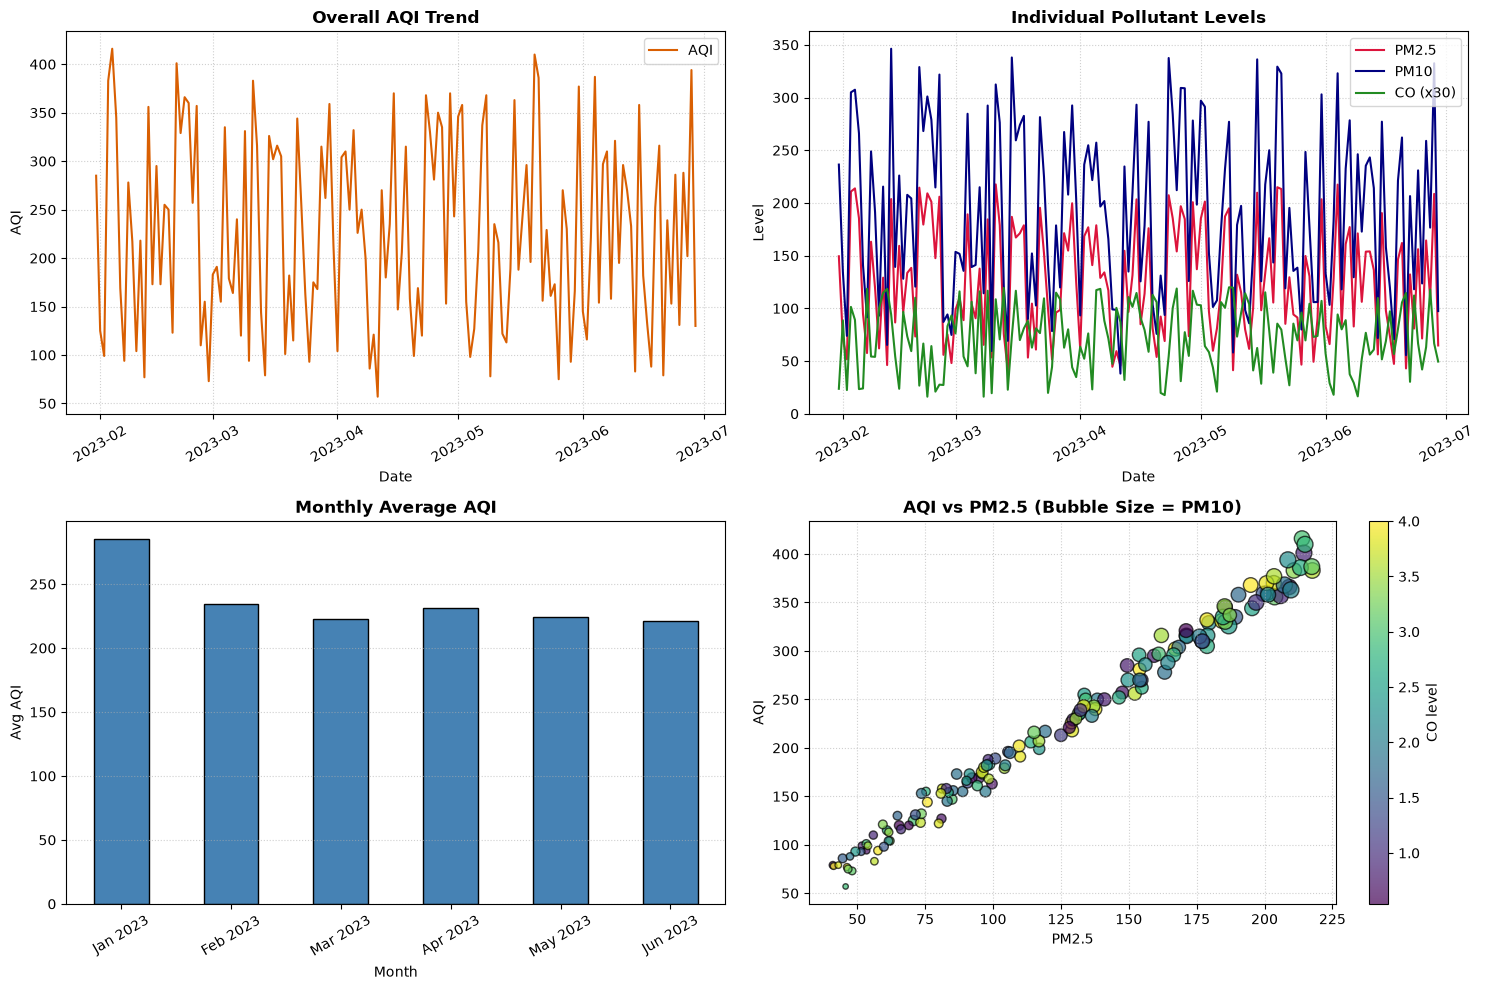

Execution complete. All plots rendered.


In [7]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CSV_PATH = "City_Air_Quality.csv"
ACTIVE_URL = "https://raw.githubusercontent.com/datasets/air-qualityindia/master/data/city_day.csv"

# 1. Load from file, remote URL, or create locally if offline/404
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    print("Loaded local City_Air_Quality.csv")
else:
    try:
        df = pd.read_csv(ACTIVE_URL)
        df.to_csv(CSV_PATH, index=False)
        print("Downloaded and saved City_Air_Quality.csv successfully")
    except Exception:
        print("Network unavailable. Generating synthetic City_Air_Quality.csv...")
        dates = pd.date_range("2023-01-01", periods=180, freq="D")
        np.random.seed(42)
        pm25 = np.random.uniform(40, 220, size=len(dates))
        pm10 = pm25 * 1.5 + np.random.normal(0, 15, size=len(dates))
        co = np.random.uniform(0.5, 4.0, size=len(dates))
        aqi = pm25 * 1.8 + np.random.normal(0, 10, size=len(dates))

        df = pd.DataFrame({
            "City": ["Delhi"] * len(dates),
            "Date": dates.strftime("%Y-%m-%d"),
            "PM2.5": pm25.round(1),
            "PM10": pm10.round(1),
            "CO": co.round(2),
            "AQI": aqi.round(0)
        })
        df.to_csv(CSV_PATH, index=False)

# 2. Filter and clean columns
if "City" in df.columns:
    df = df[df["City"].str.lower() == "delhi"].copy()
    if len(df) == 0:
        df = pd.read_csv(CSV_PATH)

df["Date"] = pd.to_datetime(df["Date"])
df = df.dropna(subset=["AQI", "PM2.5", "PM10", "CO"]).sort_values("Date").tail(150)
print(f"Loaded {len(df)} records for visualization.")

# 3. Visualizations (Tasks 4 to 9)
fig = plt.figure(figsize=(15, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# Task 4: Overall AQI Trend Over Time
ax1 = plt.subplot(2, 2, 1)
ax1.plot(df["Date"], df["AQI"], color="#d95f02", label="AQI")
ax1.set_title("Overall AQI Trend", fontweight="bold")
ax1.set_xlabel("Date")
ax1.set_ylabel("AQI")
ax1.tick_params(axis="x", rotation=30)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Task 5: Individual Pollutants Over Time
ax2 = plt.subplot(2, 2, 2)
ax2.plot(df["Date"], df["PM2.5"], label="PM2.5", color="crimson")
ax2.plot(df["Date"], df["PM10"], label="PM10", color="navy")
ax2.plot(df["Date"], df["CO"] * 30, label="CO (x30)", color="forestgreen")
ax2.set_title("Individual Pollutant Levels", fontweight="bold")
ax2.set_xlabel("Date")
ax2.set_ylabel("Level")
ax2.tick_params(axis="x", rotation=30)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

# Task 6: Monthly Average AQI (Bar Plot)
ax3 = plt.subplot(2, 2, 3)
df["Month"] = df["Date"].dt.strftime("%b %Y")
monthly = df.groupby("Month", sort=False)["AQI"].mean()
monthly.plot(kind="bar", ax=ax3, color="steelblue", edgecolor="black")
ax3.set_title("Monthly Average AQI", fontweight="bold")
ax3.set_xlabel("Month")
ax3.set_ylabel("Avg AQI")
ax3.tick_params(axis="x", rotation=30)
ax3.grid(axis="y", linestyle=":", alpha=0.6)

# Task 7 & 8: Scatter / Relationship (PM2.5 vs AQI)
ax4 = plt.subplot(2, 2, 4)
scatter = ax4.scatter(
    df["PM2.5"], df["AQI"],
    c=df["CO"], s=df["PM10"] * 0.4,
    cmap="viridis", alpha=0.7, edgecolors="k"
)
plt.colorbar(scatter, ax=ax4, label="CO level")
ax4.set_title("AQI vs PM2.5 (Bubble Size = PM10)", fontweight="bold")
ax4.set_xlabel("PM2.5")
ax4.set_ylabel("AQI")
ax4.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()
print("Execution complete. All plots rendered.")

# Assignment No. 6

Before running this cell, put your sales CSV file in the notebook's working folder and update CSV_FILE if its filename is different. The CSV must contain Region, SalesAmount, and ProductCategory columns.

Dataset loaded successfully!

=== Dataset Information ===
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB
None

=== First 5 Records ===
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION

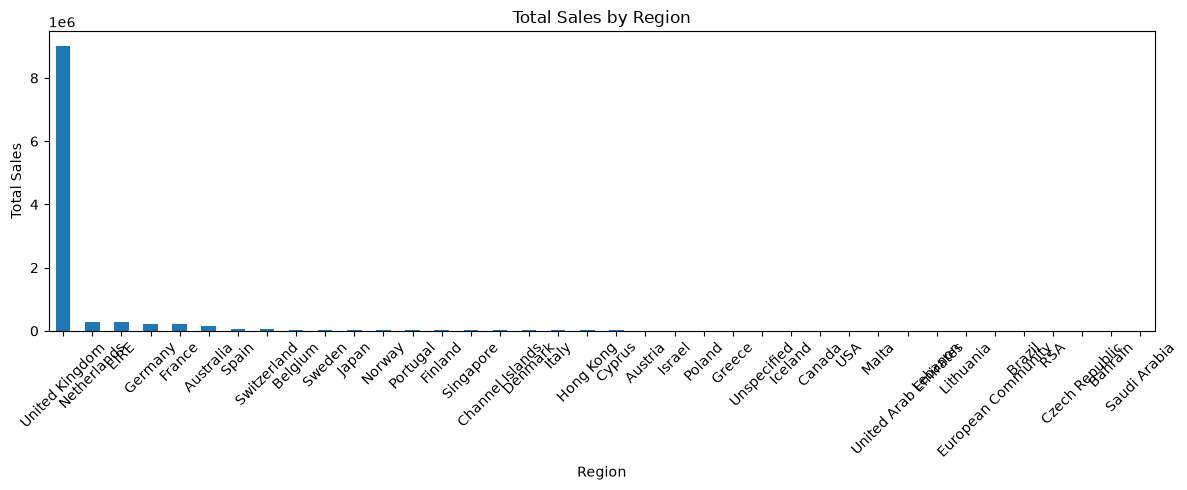

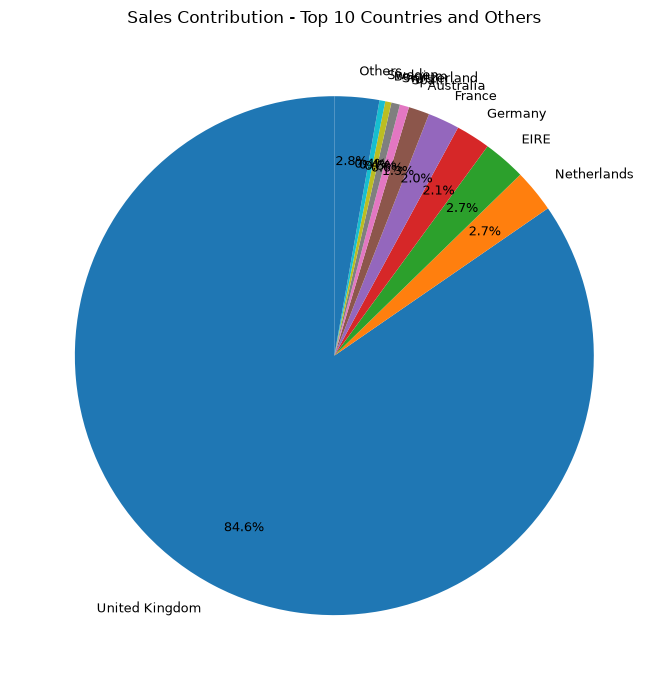

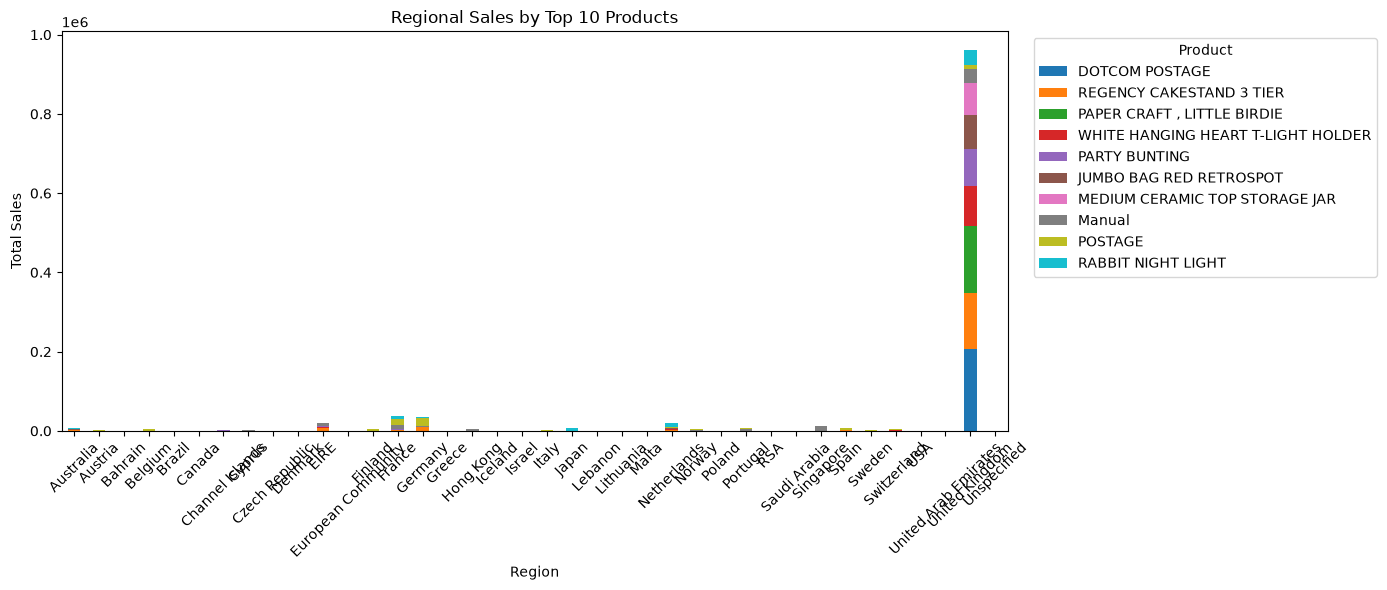


Retail Sales Analysis Completed Successfully!


In [16]:

# Practical 6: Retail Sales Analysis by Region
# Dataset: Online Retail (Kaggle)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Task 1: Load the Dataset
# --------------------------------------------------

# Specify the CSV file name
CSV_FILE = "Sales_data.csv"

# Read CSV file using cp1252 encoding
# This handles special characters like the pound (£) symbol
df = pd.read_csv(CSV_FILE, encoding="cp1252")

print("Dataset loaded successfully!")

# --------------------------------------------------
# Task 2: Understand the Dataset
# --------------------------------------------------

# Display dataset information
print("\n=== Dataset Information ===")
print(df.info())

# Display first 5 records
print("\n=== First 5 Records ===")
print(df.head())

# Display column names
print("\n=== Column Names ===")
print(df.columns.tolist())

# --------------------------------------------------
# Task 3: Data Cleaning and Transformation
# --------------------------------------------------

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove rows containing missing important values
df.dropna(
    subset=["Country", "Description", "Quantity", "UnitPrice"],
    inplace=True
)

# Convert Quantity and UnitPrice into numeric values
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

# Remove rows containing invalid numeric values
df.dropna(subset=["Quantity", "UnitPrice"], inplace=True)

# Remove returned products and invalid prices
# Negative Quantity represents returned products
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Calculate total sales amount
# Sales Amount = Quantity * Unit Price
df["SalesAmount"] = df["Quantity"] * df["UnitPrice"]

# Use Country as Region because the dataset has no Region column
df["Region"] = df["Country"]

# Use Description as ProductCategory
# The dataset contains product names, not predefined categories
df["ProductCategory"] = df["Description"]

print("\n=== Cleaned Dataset ===")
print(df.head())

# --------------------------------------------------
# Task 4: Calculate Total Sales by Region
# --------------------------------------------------

# Group data by Region and calculate total sales
region_sales = df.groupby("Region")["SalesAmount"].sum()

# Sort sales in descending order
region_sales = region_sales.sort_values(ascending=False)

print("\n=== Total Sales by Region ===")
print(region_sales)

# Find the region with the highest sales
top_region = region_sales.idxmax()
top_sales = region_sales.max()

print("\nRegion with Highest Sales:", top_region)
print("Total Sales:", round(top_sales, 2))

# --------------------------------------------------
# Task 5: Sales by Region and Product
# --------------------------------------------------

# Group data by Region and ProductCategory
# Calculate total sales for each combination
region_product_sales = df.groupby(
    ["Region", "ProductCategory"]
)["SalesAmount"].sum()

# Convert grouped data into a table
# Rows represent regions and columns represent products
region_product_table = region_product_sales.unstack(fill_value=0)

print("\n=== Sales by Region and Product ===")
print(region_product_table.head())

# --------------------------------------------------
# Task 6: Visualize Regional Sales
# --------------------------------------------------

# Plot 1: Bar Chart
# Shows total sales of each country

plt.figure(figsize=(12, 5))

region_sales.plot(kind="bar")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Plot 2: Pie Chart
# Shows sales contribution of Top 10 countries and Others

# Select the 10 countries having the highest sales
top_10 = region_sales.head(10)

# Calculate combined sales of remaining countries
others = region_sales.iloc[10:].sum()

# Combine Top 10 countries and Others
pie_data = pd.concat([
    top_10,
    pd.Series({"Others": others})
])

plt.figure(figsize=(9, 7))

plt.pie(
    pie_data,
    labels=pie_data.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75,
    textprops={"fontsize": 9}
)

plt.title("Sales Contribution - Top 10 Countries and Others")
plt.tight_layout()
plt.show()


# Plot 3: Stacked Bar Chart
# Shows sales of different products across countries

# Select the 10 highest-selling products
top_products = (
    df.groupby("ProductCategory")["SalesAmount"]
    .sum()
    .nlargest(10)
    .index
)

# Create a table containing only the Top 10 products
top_product_table = region_product_table[top_products]

# Create stacked bar chart
top_product_table.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6)
)

plt.title("Regional Sales by Top 10 Products")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.legend(
    title="Product",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# Final Message
# --------------------------------------------------

print("\nRetail Sales Analysis Completed Successfully!")
